# Why retained performance can still fail admission

Read-only archived research: all candidate admission gates still failed.
This notebook explains the PKLot/ACPDS studies and their limitations. It does not
train a model,open raw/final images,acquire data or change the app. The source
datasets provide bay polygons,not exhaustive facility or occupancy truth.

Credits: PKLot/Almeida etal./UFPR,CC BY4.0;ACPDS/Martin Marek,explicit MIT2021 grant;
existing ImageNet ResNet18 under recorded local academic terms. Development images
were repeatedly exposed. Student mastery and physical offline use are unassessed.

In [1]:
from pathlib import Path
import json,hashlib
ROOT=next(p for p in (Path.cwd().resolve(),*Path.cwd().resolve().parents) if (p/'data/manifests/guarded_region_lesson_v1.json').exists())
binding=ROOT/'data/manifests/guarded_region_lesson_v1.json'
assert hashlib.sha256(binding.read_bytes()).hexdigest()=='a7aaceeea3d72a6eb45b925625ab56b7edc5f93836236049548725a679872e65'
manifest=json.loads(binding.read_text())
for name,expected in manifest['inputs'].items():
    assert hashlib.sha256((ROOT/name).read_bytes()).hexdigest()==expected,name
archive={key:json.loads((ROOT/path).read_text()) for key,path in manifest['roles'].items() if key in ['mixed','gradients','guarded','detail']}
print('Verified archived inputs:',len(manifest['inputs']))

Verified archived inputs: 6


## Compare matched controls,not unrelated averages

Different studies used different starting weights,optimizers and source allocations.
Within each paired study,compare its own control and candidate. Equal training
budgets can still select checkpoints at different steps. IoU measures overlap with
the provided bay union;it is not occupancy accuracy.

In [2]:
print('study / arm       PKLot macro IoU   ACPDS mean IoU   selected new updates')
for study,arms in [('mixed',['control','mixed']),('guarded',['control','guarded']),('detail',['control','detail'])]:
    report=archive[study]
    for arm in arms:
        result=report['results'][arm]
        print(f"{study}/{arm:8} {result['pklot']['macro_camera_iou']:.6f}          {result['acpds']['mean_image_iou']:.6f}          {report['checkpoints'][arm]['selected_updates']}")
    print('overall admission:',report['development_gate_passed'],'shared updates:',report['updates_per_arm'])
print('Gradient diagnostic supported?',archive['gradients']['hypothesis_supported'])
print('Two fixed checkpoints do not establish the cause/timing of an AdamW regression.')

study / arm       PKLot macro IoU   ACPDS mean IoU   selected new updates
mixed/control  0.631898          0.375212          600
mixed/mixed    0.602434          0.576075          800
overall admission: False shared updates: 800
guarded/control  0.630808          0.526999          325
guarded/guarded  0.644798          0.523049          400
overall admission: False shared updates: 550
detail/control  0.649537          0.533461          50
detail/detail   0.649637          0.533652          50
overall admission: False shared updates: 200
Gradient diagnostic supported? False
Two fixed checkpoints do not establish the cause/timing of an AdamW regression.


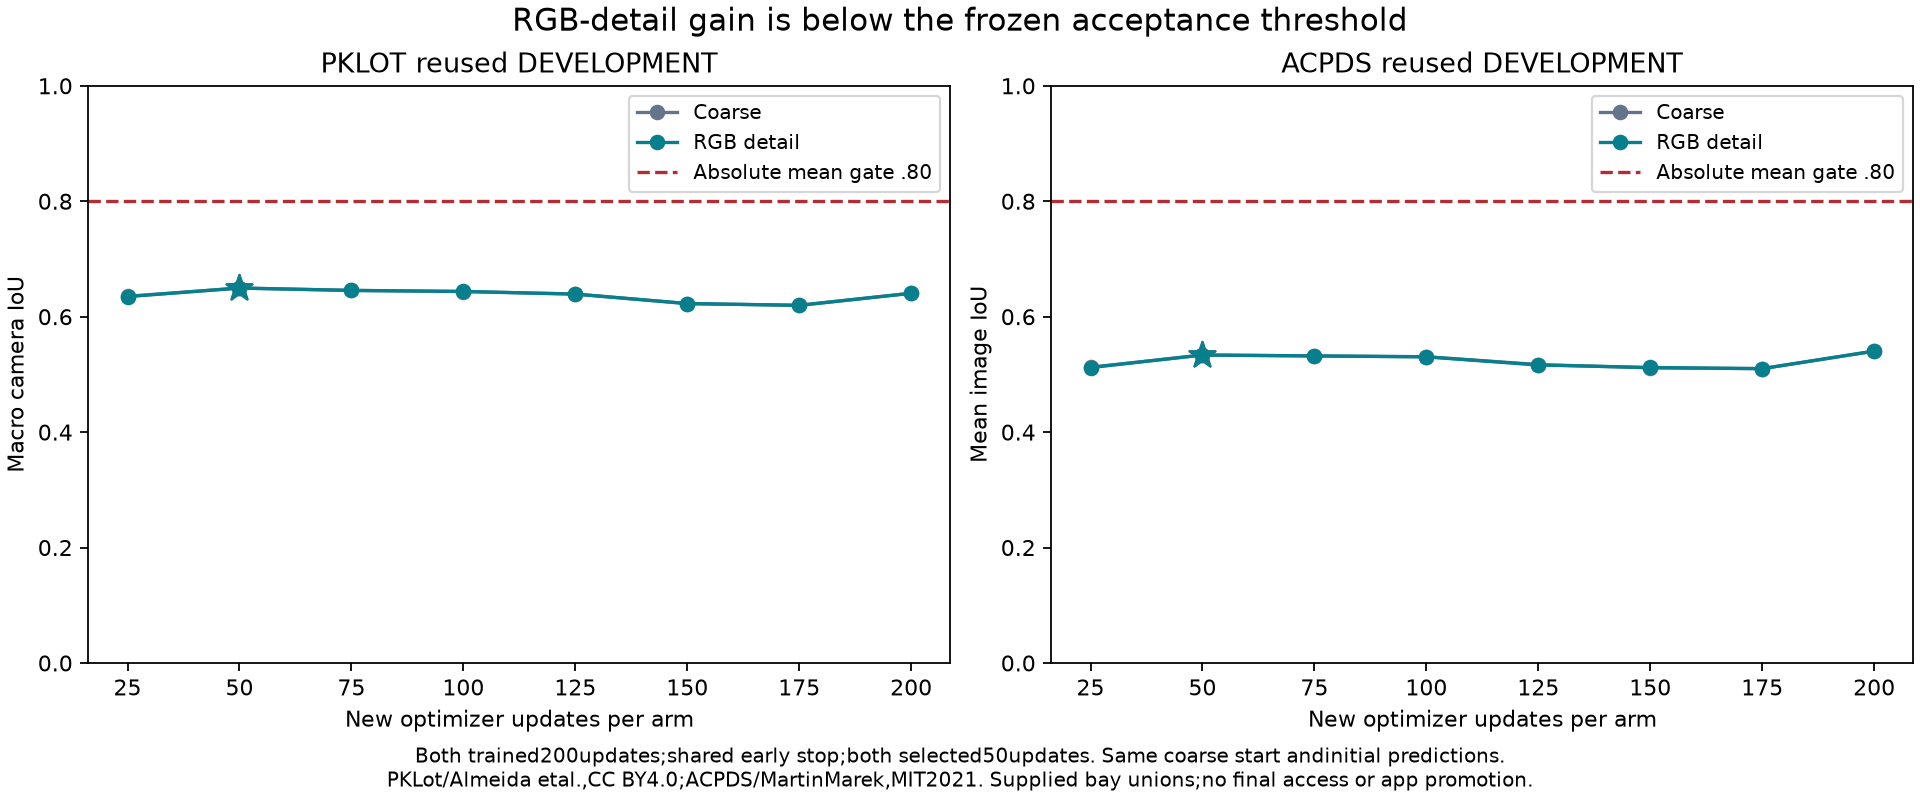

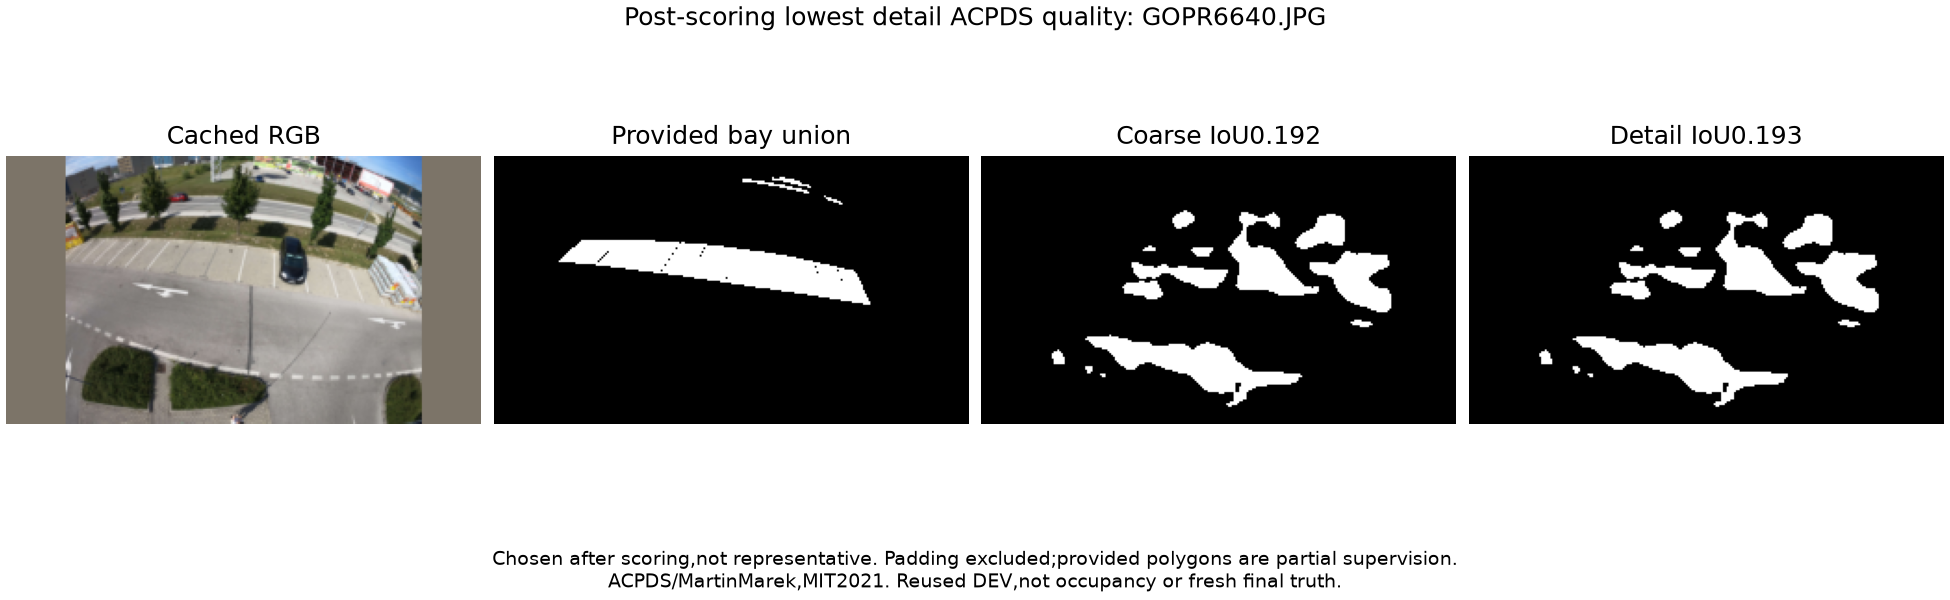

In [3]:
from IPython.display import display,Image
for key in ['capacity_plot','quality_plot']:
    display(Image(data=(ROOT/manifest['roles'][key]).read_bytes()))

## A synthetic first-order example

The following two-dimensional gradients are a teaching fixture,not parking data
or another experiment. Removing opposition and capping the auxiliary norm can
change a local directional derivative. It does not guarantee finite-step loss,
AdamW behavior,held-out quality or universal retention.

In [4]:
# SYNTHETIC fixture: a=(1,0),b=(-2,2),analytically guarded b=(0,1).
a=(1.,0.);b=(-2.,2.);guarded_b=(0.,1.)
raw_direction=tuple(-(x+y)/2 for x,y in zip(a,b))
safe_direction=tuple(-(x+y)/2 for x,y in zip(a,guarded_b))
raw_derivative=sum(x*y for x,y in zip(a,raw_direction))
safe_derivative=sum(x*y for x,y in zip(a,safe_direction))
assert raw_derivative==.5 and safe_derivative==-.5
print('Synthetic PKLot-like local derivatives:',raw_derivative,safe_derivative)
print('This is not measured image or deployment accuracy.')

Synthetic PKLot-like local derivatives: 0.5 -0.5
This is not measured image or deployment accuracy.


In [5]:
checks=dict(archived_inputs=len(manifest['inputs']),models_trained=0,new_model_calls=0,
    raw_or_final_reads=0,app_promoted=False,student_mastery_assessed=False,
    failed_candidate_admissions=sum(not archive[k]['development_gate_passed'] for k in ['mixed','guarded','detail']),
    latest_detail_gain=archive['detail']['results']['detail']['acpds']['mean_image_iou']-archive['detail']['results']['control']['acpds']['mean_image_iou'])
assert checks['archived_inputs']==6 and checks['failed_candidate_admissions']==3
assert checks['latest_detail_gain']<.02
print('GUARDED_LESSON_CHECKS='+json.dumps(checks))

GUARDED_LESSON_CHECKS={"archived_inputs": 6, "models_trained": 0, "new_model_calls": 0, "raw_or_final_reads": 0, "app_promoted": false, "student_mastery_assessed": false, "failed_candidate_admissions": 3, "latest_detail_gain": 0.00019053226543697122}


## Explain the evidence yourself

1. Why did the guarded model fail despite passing fixed-start retention checks?
2. Why is a gain around0.00019 insufficient when the frozen requirement is0.02?
3. Why do0positive TRAIN directional derivatives not establish perfect accuracy?
4. What do the worst-image diagnostic and partial polygons leave unknown?
5. Why can missing later live observations never be scored as zero error?
6. What fresh final evidence and manual/student checks remain necessary?

Running these cells does not establish independent understanding. Preserve failed
experiments andtheir gates;do not retune on consumed final groups.